# Limpieza del dataset de departamentos en Providencia

**Objetivo:** dejar todos los precios en UF (Unidad de Fomento, código ISO `CLF`) y eliminar los outliers (valores atípicos) de precio y superficie antes de entrenar un modelo.

Entrada: `data/inmuebles_providencia_geo.csv` (salida del ETL en Rust, solo avisos con coordenadas).

In [1]:
import json
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("../data/inmuebles_providencia_geo.csv")
df.groupby("moneda")["precio"].describe()

,count,mean,std,min,25%,50%,75%,max
moneda,,,,,,,,
CLF,1324.0,8.544554e+03,3.478434e+03,1949.0,6000.0,8020.0,10490.0,36000.0
CLP,41.0,2.216341e+08,8.183940e+07,130000000.0,165000000.0,200000000.0,250000000.0,540000000.0


## 1. Conversión de CLP a CLF

Algunos avisos publican el precio en pesos (`CLP`). Se convierten a UF con el **valor de la UF de hoy**, no con el valor de la fecha de publicación. La columna `uf_fecha` registra la fecha de ese valor y `precio_clp` conserva el precio original.

Fuente: API pública de mindicador.cl; si no responde, se usa findic.cl (mismo formato).

In [2]:
def uf_hoy():
    for url in ("https://mindicador.cl/api/uf", "https://findic.cl/api/uf"):
        try:
            with urllib.request.urlopen(url, timeout=15) as r:
                hoy = json.load(r)["serie"][0]
            return hoy["fecha"][:10], hoy["valor"]
        except OSError as e:
            print(f"{url} no responde: {e}")
    raise RuntimeError("no hay fuente disponible para la UF")


uf_fecha, uf = uf_hoy()
print(f"UF del {uf_fecha}: ${uf:,.2f}")

https://mindicador.cl/api/uf no responde: The read operation timed out
UF del 2026-10-23: $41,205.16


In [3]:
clp = df["moneda"] == "CLP"
df["precio_clp"] = df["precio"].where(clp)
df["precio_uf"] = df["precio"].where(~clp, (df["precio"] / uf).round(2))
df["uf_fecha"] = np.where(clp, uf_fecha, None)
df = df.drop(columns=["precio", "moneda"])
df.loc[clp, ["titulo", "precio_clp", "precio_uf", "uf_fecha"]].head()

,titulo,precio_clp,precio_uf,uf_fecha
31,"Cercano A Metro Salvador, Piso Dos, Vista Norte.",188000000.0,4562.54,2026-10-23
64,Amplio Y Acogedor Departamento Refaccionado - ...,380000000.0,9222.15,2026-10-23
66,Amplio Y Cómodo Departamento En Providencia,250000000.0,6067.20,2026-10-23
69,Amplio Departamento En Barrio Los Obispos,155000000.0,3761.66,2026-10-23
94,Espacioso Depto 2d/1b A Pasos Del Metro Manuel...,180000000.0,4368.38,2026-10-23


## 2. Outliers de precio y superficie

Primero se eliminan las filas sin precio o sin superficie. Luego se aplica la regla del IQR (rango intercuartílico): un valor es atípico si queda fuera de `[Q1 - 1,5·IQR, Q3 + 1,5·IQR]`.

Precio y superficie tienen cola larga a la derecha. Por eso la regla se aplica sobre el **logaritmo** de cada variable: así no se descartan, por ejemplo, todos los departamentos grandes.

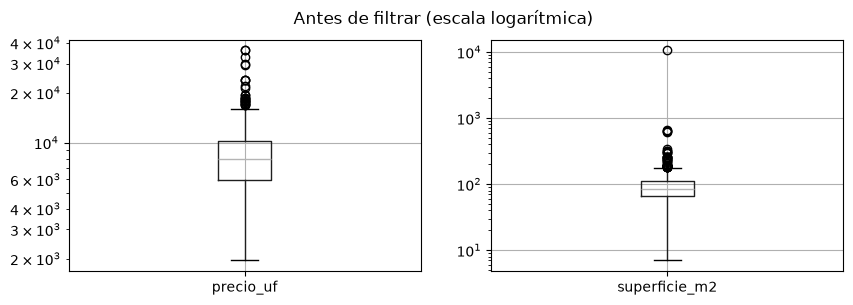

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
df.boxplot("precio_uf", ax=ax[0])
df.boxplot("superficie_m2", ax=ax[1])
ax[0].set_yscale("log")
ax[1].set_yscale("log")
fig.suptitle("Antes de filtrar (escala logarítmica)");

In [5]:
def dentro_iqr(s, k=1.5):
    x = np.log(s)
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return x.between(q1 - k * iqr, q3 + k * iqr)


n0 = len(df)
df = df.dropna(subset=["precio_uf", "superficie_m2"])
n1 = len(df)
ok = dentro_iqr(df["precio_uf"]) & dentro_iqr(df["superficie_m2"])
print(f"filas iniciales: {n0}")
print(f"sin precio o superficie: {n0 - n1}")
print(f"outliers: {(~ok).sum()}")
df.loc[~ok, ["titulo", "precio_uf", "superficie_m2", "direccion"]].sort_values("superficie_m2")

filas iniciales: 1365
sin precio o superficie: 4
outliers: 40


,titulo,precio_uf,superficie_m2,direccion
755,Hermoso Dpto 2d-2b-1est-1bd Providencia,4590.00,7.0,"PROVIDENCIA 455, Salvador, Providencia"
1293,Biarritz / Pedro De Valdivia,9300.00,14.0,"Biarritz 1945, Providencia, Pedro De Valdivia,..."
477,Departamento A La Venta En Providencia Metro L...,3100.00,22.0,"Carlos Antúnez 2319, Providencia, Los Leones, ..."
535,Departamento En Venta De 1 Dorm. En Providencia,3800.00,25.0,"Francisco Antonio Encina, Pedro De Valdivia, P..."
1202,"Estudio/ Cerca Metro Pedro De Valdivia, Estac,...",3490.00,25.0,"Av. Pedro De Valdivia 150, Providencia, Pedro ..."
346,Inversión Depto Estudio Airbnb Pedro De Valdivia,3390.00,25.0,"Avenida Pedro De Valdivia, 1 - 300, Pedro De V..."
1030,1d/1b | Providencia | Metro Pedro De Valdivia,3600.00,25.0,"Pedro De Valdivia, Providencia"
298,Depto 1d + 1b En Piso 15 A Pasos Del Metro Los...,4300.00,25.0,"Av. Providencia 2196, 7.5099e+06 - 7.5102e+06 ..."
1300,Rebajado!! P. De Valdivia C_423899,3490.00,25.0,"Pedro De Valdivia, Providencia"
297,Depto 1d + 1b A Pasos Del Metro Pedro De Valdivia,3203.48,28.0,"Barcelona 2126, 7.5099e+06 - 7.5102e+06 Santia..."


,precio_uf,superficie_m2
count,1321.000000,1321.000000
mean,8331.557540,89.469341
std,2979.344089,33.839046
min,3108.000000,31.000000
25%,5990.000000,66.000000
50%,7990.000000,85.000000
75%,10250.000000,110.000000
max,22000.000000,230.000000


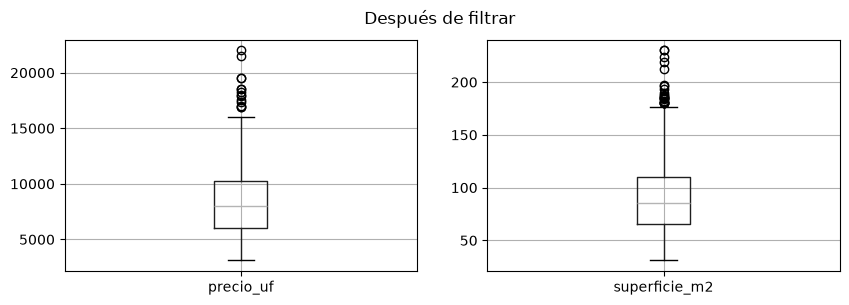

In [6]:
df = df[ok]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
df.boxplot("precio_uf", ax=ax[0])
df.boxplot("superficie_m2", ax=ax[1])
fig.suptitle("Después de filtrar")
df[["precio_uf", "superficie_m2"]].describe()

## 3. Resultado

In [7]:
df.to_csv("../data/inmuebles_providencia_limpio.csv", index=False)
print(f"{len(df)} avisos en data/inmuebles_providencia_limpio.csv, precios en UF del {uf_fecha}")

1321 avisos en data/inmuebles_providencia_limpio.csv, precios en UF del 2026-10-23
